In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix


In [ ]:
#carregamento do dataset rotulado
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/MonografiaI/Artigo/dataset_mensagens_rotuladas1.csv'
df_rotulado = pd.read_csv(file_path)

df_rotulado.shape
df_rotulado.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Unnamed: 0,mensagem_erro,rotulo
0,13,clang: error: linker command failed with exit ...,OUT
1,24,clang: error: linker command failed with exit ...,OUT
2,35,clang: error: linker command failed with exit ...,OUT
3,82,clang: error: linker command failed with exit ...,OUT
4,87,clang: error: linker command failed with exit ...,OUT


In [ ]:
X = df_rotulado["mensagem_erro"]
y = df_rotulado["rotulo"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


In [ ]:
modelo = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

modelo.fit(X_train_tfidf, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
y_pred = modelo.predict(X_test_tfidf)

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

          C1       0.97      0.95      0.96        38
          C2       0.98      0.95      0.97        88
          C3       0.73      0.89      0.80         9
          C4       0.92      1.00      0.96        11
          C5       0.75      0.75      0.75         4
          C6       0.00      0.00      0.00         1
          C7       0.80      1.00      0.89         4
         OUT       1.00      1.00      1.00         5

    accuracy                           0.94       160
   macro avg       0.77      0.82      0.79       160
weighted avg       0.94      0.94      0.94       160



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
#matriz de confusão
cm = confusion_matrix(y_test, y_pred, labels=modelo.classes_)  # garante ordem correta das classes

# Exibir matriz de confusão numérica
print("Matriz de confusão (valores absolutos):")
print(cm)

Matriz de confusão (valores absolutos):
[[36  0  0  1  1  0  0  0]
 [ 1 84  3  0  0  0  0  0]
 [ 0  1  8  0  0  0  0  0]
 [ 0  0  0 11  0  0  0  0]
 [ 0  1  0  0  3  0  0  0]
 [ 0  0  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  4  0]
 [ 0  0  0  0  0  0  0  5]]


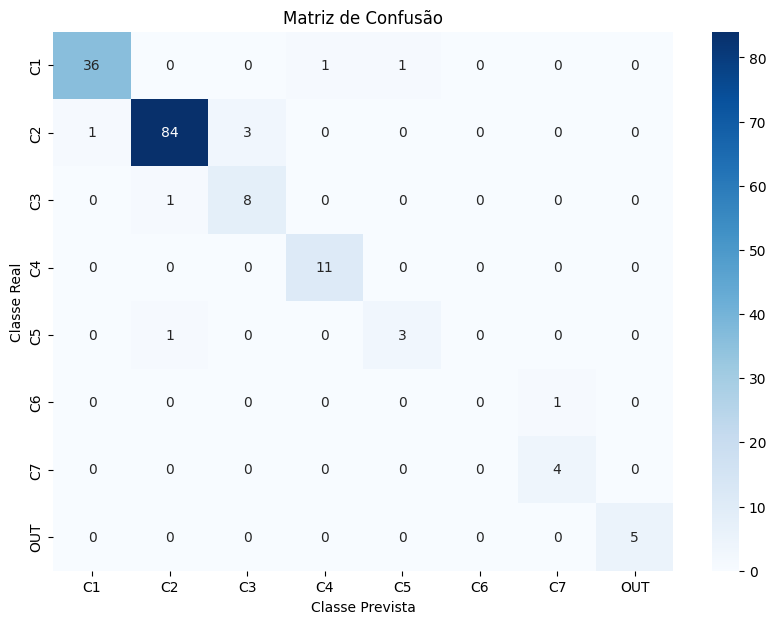

In [ ]:
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=modelo.classes_,
            yticklabels=modelo.classes_)
plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.title('Matriz de Confusão')
plt.show()